# 06 · Comparación de resultados

Respondemos tres preguntas:

1. **¿Cómo cambian los atípicos al limpiar los datos?** (crudo vs limpio)
2. **¿DBSCAN y K-prototypes encuentran los mismos atípicos?**
3. **¿Qué tipo de contratos son atípicos y dónde están?** (todos los contratos limpios)

In [ ]:
from pathlib import Path

RAIZ = Path("..")
DATA = RAIZ / "data"
MUESTRAS = DATA / "muestras"
RESULTADOS = RAIZ / "resultados"
MODELOS = RESULTADOS / "modelos"
FIGURAS = RESULTADOS / "figuras"
TABLAS = RESULTADOS / "tablas"
for carpeta in [MUESTRAS, MODELOS, FIGURAS, TABLAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NUMERICAS = [
    "log_valor_contrato",          # log(1 + valor del contrato)
    "log_ratio_contrato_proceso",  # log(valor del contrato / valor estimado del proceso)
    "ratio_adiciones",             # valor adicionado / valor del contrato
    "log_plazo_dias",              # log(1 + plazo en días)
    "log_adiciones_dias",          # log(1 + días adicionados)
    "slog_dias_firma_cargue",      # log "con signo" de los días entre la firma y la publicación
]
CATEGORICAS = [
    "modalidad_de_contratacion",
    "tipo_de_contrato",
    "orden_entidad",
    "nombre_grupo",
    "tipo_identifi_del_contratista",
    "destino_gasto",
    "estado_del_proceso",
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

muestras = {"cruda": pd.read_parquet(MUESTRAS / "muestra_cruda.parquet"),
            "limpia": pd.read_parquet(MUESTRAS / "muestra_limpia.parquet")}
res = {}
for escenario, datos in muestras.items():
    datos = datos.merge(pd.read_parquet(RESULTADOS / f"dbscan_{escenario}.parquet"), on="row_id")
    datos = datos.merge(pd.read_parquet(RESULTADOS / f"kprototypes_{escenario}.parquet"), on="row_id")
    res[escenario] = datos
print({k: len(v) for k, v in res.items()})

{'cruda': 50000, 'limpia': 50000}


## 1. Crudo vs limpio

In [2]:
filas = []
for escenario in ["cruda", "limpia"]:
    r = res[escenario]
    filas.append({
        "escenario": escenario,
        "k (K-prototypes)": r.kp_cluster.nunique(),
        "clusters DBSCAN": r.loc[r.db_cluster >= 0, "db_cluster"].nunique(),
        "% ruido DBSCAN": round(100 * r.db_ruido.mean(), 2),
        "% atípicos K-prototypes": round(100 * r.kp_atipico.mean(), 2),
    })
tabla_escenarios = pd.DataFrame(filas)
tabla_escenarios.to_csv(TABLAS / "crudo_vs_limpio.csv", index=False)
tabla_escenarios

,escenario,k (K-prototypes),clusters DBSCAN,% ruido DBSCAN,% atípicos K-prototypes
0,cruda,2,4,0.62,4.81
1,limpia,4,1,1.46,3.01


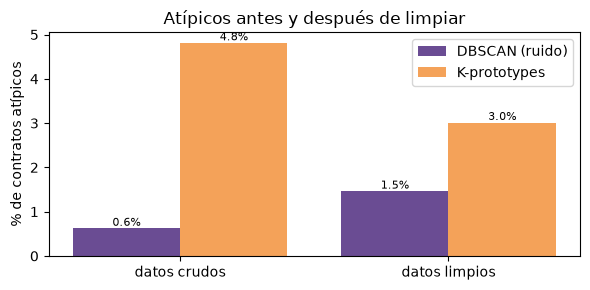

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(2)
ax.bar(x - 0.2, tabla_escenarios["% ruido DBSCAN"], 0.4, label="DBSCAN (ruido)", color="#6a4c93")
ax.bar(x + 0.2, tabla_escenarios["% atípicos K-prototypes"], 0.4, label="K-prototypes", color="#f4a259")
ax.set_xticks(x, ["datos crudos", "datos limpios"])
ax.set_ylabel("% de contratos atípicos")
ax.set_title("Atípicos antes y después de limpiar")
ax.legend()
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "atipicos_crudo_vs_limpio.png", dpi=130)
plt.show()

### 1.1 ¿Cuántos atípicos de los datos crudos eran en realidad errores de los datos?

Cada registro de la muestra cruda tiene su `motivo_exclusion`. Si un atípico crudo tiene motivo (duplicado, sin contrato, error de captura…), es un **falso positivo**: desaparece al limpiar.

In [4]:
cruda = res["cruda"].copy()
cruda["motivo"] = cruda["motivo_exclusion"].fillna("válido (sigue después de limpiar)")

origen = pd.DataFrame({
    "% de toda la muestra": cruda["motivo"].value_counts(normalize=True) * 100,
    "% de atípicos DBSCAN": cruda.loc[cruda.db_ruido, "motivo"].value_counts(normalize=True) * 100,
    "% de atípicos K-prototypes": cruda.loc[cruda.kp_atipico, "motivo"].value_counts(normalize=True) * 100,
}).fillna(0).round(1).sort_values("% de toda la muestra", ascending=False)
origen.to_csv(TABLAS / "origen_atipicos_crudos.csv")
origen

,% de toda la muestra,% de atípicos DBSCAN,% de atípicos K-prototypes
motivo,,,
válido (sigue después de limpiar),86.8,54.5,82.7
sin contrato firmado,9.1,1.6,2.2
duplicado,3.0,1.9,3.0
error de captura: valor,0.7,35.1,10.2
error de captura: fecha,0.1,0.3,1.2
otra moneda,0.1,3.2,0.3
error de captura: plazo,0.0,1.3,0.2
error de captura: adiciones,0.0,1.9,0.2


In [5]:
for metodo, col in [("DBSCAN", "db_ruido"), ("K-prototypes", "kp_atipico")]:
    falsos = (cruda[col] & cruda.motivo_exclusion.notna()).sum()
    print(f"{metodo}: {100 * falsos / cruda[col].sum():.1f}% de los atípicos crudos eran registros que la limpieza elimina")

DBSCAN: 45.5% de los atípicos crudos eran registros que la limpieza elimina
K-prototypes: 17.3% de los atípicos crudos eran registros que la limpieza elimina


### 1.2 ¿Qué agrupa K-prototypes en los datos crudos?

In [6]:
pd.crosstab(cruda["motivo"], cruda["kp_cluster"])

kp_cluster,0,1
motivo,,
duplicado,0,1525
error de captura: adiciones,0,6
error de captura: fecha,0,60
error de captura: plazo,0,14
error de captura: valor,17,344
otra moneda,0,71
sin contrato firmado,4221,349
válido (sigue después de limpiar),0,43393


## 2. DBSCAN vs K-prototypes

Medimos qué tanto coinciden los atípicos:

* **Jaccard** = atípicos en ambos / atípicos en al menos uno (0 = nada en común, 1 = idénticos).
* **Kappa de Cohen**: acuerdo descontando el que se daría por azar (0 = azar, 1 = acuerdo total).

DBSCAN y K-prototypes marcan cantidades distintas de atípicos, lo que baja el Jaccard. Por eso también comparamos a **igual tamaño**: los N contratos con mayor puntaje de K-prototypes, con N = número de ruido de DBSCAN.

In [7]:
def comparar(a, b):
    return {"DBSCAN": int(a.sum()), "K-prototypes": int(b.sum()), "ambos": int((a & b).sum()),
            "Jaccard": round((a & b).sum() / (a | b).sum(), 3), "Kappa": round(cohen_kappa_score(a, b), 3)}


filas = []
for escenario in ["cruda", "limpia"]:
    r = res[escenario]
    top_n = r.kp_puntaje.rank(ascending=False) <= r.db_ruido.sum()
    filas.append({"escenario": escenario, "K-prototypes": "regla Q3 + 3·IQR", **comparar(r.db_ruido, r.kp_atipico)})
    filas.append({"escenario": escenario, "K-prototypes": "top-N (mismo N que DBSCAN)", **comparar(r.db_ruido, top_n)})
concordancia = pd.DataFrame(filas)
concordancia.to_csv(TABLAS / "concordancia_metodos.csv", index=False)
concordancia

,escenario,K-prototypes,DBSCAN,ambos,Jaccard,Kappa
0,cruda,2405,308,266,0.109,0.187
1,cruda,308,308,123,0.249,0.396
2,limpia,1504,730,471,0.267,0.410
3,limpia,730,730,372,0.342,0.502


## 3. Todos los contratos limpios (≈5,6 millones)

Los resultados de la población están en Parquet (notebook 05). Para resumirlos usamos Spark otra vez.

In [ ]:
import os
import sys
import subprocess

if sys.platform == "darwin":
    os.environ["JAVA_HOME"] = subprocess.check_output(["/usr/libexec/java_home", "-v", "17"]).decode().strip()

os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder.appName("secop-resultados")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
gold = spark.read.parquet(str(DATA / "gold" / "contratos_puntuados.parquet"))
gold = gold.withColumn(
    "grupo",
    F.when(F.col("db_ruido") & F.col("kp_atipico"), "1. atípico en ambos")
     .when(F.col("db_ruido"), "2. solo DBSCAN")
     .when(F.col("kp_atipico"), "3. solo K-prototypes")
     .otherwise("4. normal"),
)
total = gold.count()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 18:29:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [ ]:
conteo = gold.groupBy("db_ruido", "kp_atipico").count().toPandas()
def contar(db, kp): return int(conteo.query("db_ruido == @db and kp_atipico == @kp")["count"].sum())
ambos, solo_db, solo_kp = contar(True, True), contar(True, False), contar(False, True)
print(f"Contratos: {total:,}")
print(f"Ruido DBSCAN: {ambos + solo_db:,} ({100 * (ambos + solo_db) / total:.2f}%)")
print(f"Atípicos K-prototypes: {ambos + solo_kp:,} ({100 * (ambos + solo_kp) / total:.2f}%)")
print(f"Atípicos en AMBOS: {ambos:,} ({100 * ambos / total:.2f}%)   Jaccard = {ambos / (ambos + solo_db + solo_kp):.3f}")

Contratos: 5,628,310
Ruido DBSCAN: 82,922 (1.47%)
Atípicos K-prototypes: 170,755 (3.03%)
Atípicos en AMBOS: 54,311 (0.96%)   Jaccard = 0.272


### 3.1 ¿Cómo son los contratos atípicos?

In [10]:
perfil = (gold.groupBy("grupo").agg(
    F.count("*").alias("contratos"),
    F.round(F.percentile_approx("valor_contrato", 0.5) / 1e6, 1).alias("valor mediano (M COP)"),
    F.percentile_approx("plazo_dias", 0.5).alias("plazo mediano (días)"),
    F.round(F.avg((F.col("ratio_adiciones") > 0.5).cast("int")) * 100, 2).alias("% con adiciones > 50%"),
    F.round(F.avg((F.col("dias_firma_cargue") > 3).cast("int")) * 100, 1).alias("% publicado > 3 días después"),
).orderBy("grupo").toPandas())
perfil.to_csv(TABLAS / "perfil_atipicos.csv", index=False)
perfil

,grupo,contratos,valor mediano (M COP),plazo mediano (días),% con adiciones > 50%,% publicado > 3 días después
0,1. atípico en ambos,54311,13.5,90.0,27.26,56.1
1,2. solo DBSCAN,28611,50.5,90.0,10.68,36.5
2,3. solo K-prototypes,116444,200.0,180.0,0.58,69.6
3,4. normal,5428944,8.3,90.0,0.25,65.8


**Lift:** cuántas veces más frecuente es una categoría entre los atípicos que en el total. Un lift de 5 quiere decir que esa categoría aparece 5 veces más entre los atípicos de lo que se esperaría.

In [11]:
def lift(variable, bandera):
    t = (gold.groupBy(variable)
         .agg(F.count("*").alias("contratos"), F.sum(F.col(bandera).cast("int")).alias("atipicos"))
         .toPandas())
    t["% del total"] = 100 * t.contratos / t.contratos.sum()
    t["% de los atípicos"] = 100 * t.atipicos / t.atipicos.sum()
    t["lift"] = t["% de los atípicos"] / t["% del total"]
    return t[t.contratos >= 1000].sort_values("lift", ascending=False).round(2)


lift("modalidad_de_contratacion", "db_ruido").head(6)

,modalidad_de_contratacion,contratos,atipicos,% del total,% de los atípicos,lift
11,LICITACION PUBLICA,14672,2354,0.26,2.84,10.89
6,LICITACION OBRA PUBLICA,13911,1439,0.25,1.74,7.02
7,SUBASTA,31299,2981,0.56,3.59,6.46
8,CONCURSO DE MERITOS ABIERTO,21812,1445,0.39,1.74,4.50
10,CONTRATOS Y CONVENIOS CON MAS DE DOS PARTES,64042,2314,1.14,2.79,2.45
2,SELECCION ABREVIADA DE MENOR CUANTIA (LEY 1150...,67218,1837,1.19,2.22,1.85


In [12]:
lift("modalidad_de_contratacion", "kp_atipico").head(6)

,modalidad_de_contratacion,contratos,atipicos,% del total,% de los atípicos,lift
6,LICITACION OBRA PUBLICA,13911,4212,0.25,2.47,9.98
11,LICITACION PUBLICA,14672,3519,0.26,2.06,7.91
10,CONTRATOS Y CONVENIOS CON MAS DE DOS PARTES,64042,5891,1.14,3.45,3.03
7,SUBASTA,31299,1828,0.56,1.07,1.93
8,CONCURSO DE MERITOS ABIERTO,21812,1217,0.39,0.71,1.84
12,REGIMEN ESPECIAL,2111686,87117,37.52,51.02,1.36


In [13]:
lift("tipo_de_contrato", "kp_atipico").head(6)

,tipo_de_contrato,contratos,atipicos,% del total,% de los atípicos,lift
11,CREDITO,1846,1492,0.03,0.87,26.64
5,COMODATO,2042,1127,0.04,0.66,18.19
7,ACUERDO MARCO,1471,531,0.03,0.31,11.90
13,CONCESION,1007,194,0.02,0.11,6.35
12,OTRO TIPO DE CONTRATO,221978,25593,3.94,14.99,3.80
14,OBRA,143746,13698,2.55,8.02,3.14


### 3.2 Clusters de K-prototypes: ¿hay algún grupo pequeño de contratos raros?

In [14]:
gold.groupBy("kp_cluster").agg(
    F.count("*").alias("contratos"),
    F.round(100 * F.avg(F.col("kp_atipico").cast("int")), 1).alias("% atípicos K-prototypes"),
    F.round(100 * F.avg(F.col("db_ruido").cast("int")), 1).alias("% ruido DBSCAN"),
    F.round(F.percentile_approx("ratio_adiciones", 0.5), 2).alias("adiciones/valor (mediana)"),
).orderBy("kp_cluster").toPandas()

,kp_cluster,contratos,% atípicos K-prototypes,% ruido DBSCAN,adiciones/valor (mediana)
0,0,743817,2.7,2.7,0.00
1,1,1599187,1.2,0.5,0.00
2,2,424707,5.5,9.7,0.38
3,3,2860599,3.8,0.5,0.00


### 3.3 Distribución territorial

In [15]:
departamentos = (gold.groupBy("departamento_entidad").agg(
    F.count("*").alias("contratos"),
    F.sum(F.col("db_ruido").cast("int")).alias("ruido_dbscan"),
    F.sum(F.col("kp_atipico").cast("int")).alias("atipicos_kprototypes"),
    F.sum((F.col("db_ruido") & F.col("kp_atipico")).cast("int")).alias("atipicos_ambos"),
).toPandas())
for col in ["ruido_dbscan", "atipicos_kprototypes", "atipicos_ambos"]:
    departamentos["%_" + col] = (100 * departamentos[col] / departamentos.contratos).round(2)
departamentos = departamentos.sort_values("%_atipicos_ambos", ascending=False)
departamentos.to_csv(TABLAS / "atipicos_por_departamento.csv", index=False)   # para el mapa
departamentos.head(10)

,departamento_entidad,contratos,ruido_dbscan,atipicos_kprototypes,atipicos_ambos,%_ruido_dbscan,%_atipicos_kprototypes,%_atipicos_ambos
11,SIN DATO,788,211,184,143,26.78,23.35,18.15
28,BOGOTA D.C.,468639,29504,52999,21313,6.30,11.31,4.55
13,COLOMBIA,161,6,26,6,3.73,16.15,3.73
1,VAUPES,18211,588,730,410,3.23,4.01,2.25
10,ANTIOQUIA,824268,14490,29220,9149,1.76,3.54,1.11
15,CALDAS,167819,2933,5196,1846,1.75,3.10,1.10
4,"SAN ANDRES, PROVIDENCIA Y SANTA CATALINA",31753,277,841,260,0.87,2.65,0.82
21,TOLIMA,212377,2185,3951,1510,1.03,1.86,0.71
12,QUINDIO,87122,955,1523,608,1.10,1.75,0.70
23,NORTE DE SANTANDER,207640,2161,3482,1389,1.04,1.68,0.67


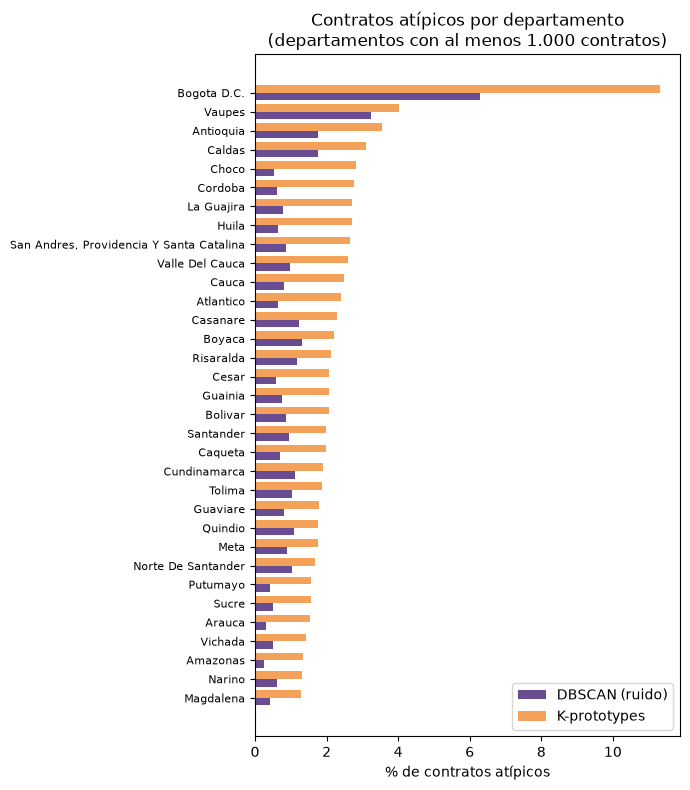

In [16]:
d = departamentos[departamentos.contratos >= 1000].sort_values("%_atipicos_kprototypes")
fig, ax = plt.subplots(figsize=(7, 8))
y = np.arange(len(d))
ax.barh(y - 0.2, d["%_ruido_dbscan"], 0.4, label="DBSCAN (ruido)", color="#6a4c93")
ax.barh(y + 0.2, d["%_atipicos_kprototypes"], 0.4, label="K-prototypes", color="#f4a259")
ax.set_yticks(y, d.departamento_entidad.str.title(), fontsize=8)
ax.set_xlabel("% de contratos atípicos")
ax.set_title("Contratos atípicos por departamento\n(departamentos con al menos 1.000 contratos)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURAS / "atipicos_por_departamento.png", dpi=130)
plt.show()

### 3.4 Lista de contratos para revisar (atípicos en ambos métodos)

In [17]:
revisar = (gold.filter(F.col("db_ruido") & F.col("kp_atipico"))
           .orderBy(F.desc("kp_puntaje"))
           .select("uid", "departamento_entidad", "nombre_entidad", "modalidad_de_contratacion", "tipo_de_contrato",
                   "valor_contrato", "valor_adiciones", "plazo_dias", "dias_firma_cargue", "kp_puntaje",
                   "objeto_del_contrato_a_la_firma", "ruta_proceso_en_secop_i")
           .limit(200).toPandas())
revisar.to_csv(TABLAS / "top200_atipicos_ambos_metodos.csv", index=False)
revisar.head(10)[["departamento_entidad", "tipo_de_contrato", "valor_contrato", "valor_adiciones", "plazo_dias", "kp_puntaje"]]

,departamento_entidad,tipo_de_contrato,valor_contrato,valor_adiciones,plazo_dias,kp_puntaje
0,BOGOTA D.C.,COMPRAVENTA,3.247842e+11,0.0,1260.0,506.347809
1,BOGOTA D.C.,OTRO TIPO DE CONTRATO,1.000000e+11,0.0,1050.0,461.416534
2,BOGOTA D.C.,OTRO TIPO DE CONTRATO,9.512709e+10,0.0,750.0,459.429047
3,BOGOTA D.C.,OTRO TIPO DE CONTRATO,4.110000e+10,0.0,3240.0,429.678528
4,HUILA,OTRO TIPO DE CONTRATO,4.000000e+10,0.0,3600.0,428.801208
5,LA GUAJIRA,OTRO TIPO DE CONTRATO,2.648029e+10,0.0,3600.0,414.113342
6,BOGOTA D.C.,OTRO TIPO DE CONTRATO,2.656721e+10,0.0,1050.0,413.887604
7,VALLE DEL CAUCA,COMODATO,2.002951e+10,0.0,1800.0,404.100494
8,MAGDALENA,OTRO TIPO DE CONTRATO,1.500000e+10,0.0,2880.0,394.583771
9,META,CREDITO,1.370000e+10,0.0,3600.0,391.362396


In [18]:
spark.stop()

## 4. Conclusiones

### ¿Cómo cambian los atípicos al limpiar los datos?

1. **La limpieza deja fuera el 13,3 % de los registros:** 9,2 % son procesos sin contrato firmado, 3,1 % UIDs duplicados, 1 % errores de captura y 0,15 % contratos en otra moneda.
2. **Muchos atípicos de los datos crudos eran errores de los datos.** El **45,5 % del ruido de DBSCAN** y el **17,3 % de los atípicos de K-prototypes** en la muestra cruda son registros que la limpieza elimina. El caso más claro son los errores de captura en el valor: son el 0,7 % de los registros, pero el **35 % del ruido de DBSCAN** (unas 50 veces más de lo esperado).
3. **Sin limpiar, K-prototypes encuentra una estructura equivocada.** La silueta elige k = 2, y uno de los dos clusters (4.238 registros) **no tiene ni un solo contrato válido**: 4.221 son procesos sin contrato firmado. Con datos limpios elige k = 4, con grupos interpretables: mínima cuantía con persona jurídica, régimen especial, contratación directa con adiciones y contratación directa municipal.
4. **La limpieza cambia el tipo de atípicos, no solo la cantidad.** En los datos crudos, DBSCAN marca menos atípicos (0,6 % frente a 1,5 %) y la mitad son errores. Los registros con valores en 0 forman zonas muy densas que se vuelven "normales" y deforman la curva de k-distancias.

### ¿DBSCAN y K-prototypes encuentran los mismos atípicos?

5. **Coinciden de forma moderada, y coinciden más después de limpiar.** Jaccard sube de 0,11 a 0,27 y Kappa de 0,19 a 0,41; comparando a igual tamaño (top-N), Kappa = 0,50. Con datos sucios, cada método "persigue" un tipo distinto de error.
6. **Detectan cosas distintas:**
   * **Atípicos en ambos** (54.311 contratos, 0,96 %): el **27 % tiene adiciones mayores al 50 % del valor inicial**, el tope del art. 40 de la Ley 80 de 1993. En los contratos normales esa proporción es 0,25 %, unas 100 veces menos. **Es la lista más útil para revisar.**
   * **Solo K-prototypes:** contratos de magnitud extrema (valor mediano de $200 millones frente a $8 millones en los normales; plazos largos), muy lejos del contrato típico de su grupo.
   * **Solo DBSCAN:** combinaciones poco comunes de categorías y valores, aunque los montos no sean extremos.
7. **Limitación de K-prototypes:** el cluster 2 agrupa contratos con adiciones (mediana de 38 % del valor). Como ese grupo tiene su propio prototipo, sus contratos con adiciones grandes quedan "cerca" de él: K-prototypes marca solo el 5,5 % del cluster, mientras DBSCAN marca el 9,7 %. Un método de partición puede **esconder** anomalías que se parecen entre sí.
8. **DBSCAN encontró un solo cluster en los datos limpios.** Los contratos no forman grupos de densidad separados sino una nube continua, así que DBSCAN funciona como **detector de atípicos** y no como agrupador. K-prototypes sí entrega una segmentación interpretable. Por eso los dos métodos se complementan.

### ¿Qué tipo de contratos y dónde?

9. Las modalidades competitivas y poco frecuentes están sobrerrepresentadas entre los atípicos: **licitación pública** (lift 10,9 en DBSCAN), **licitación de obra pública** (lift 10,0 en K-prototypes) y subasta. También tipos de contrato raros: **crédito** (lift 26,6) y **comodato** (lift 18,2).
10. Por territorio, **Bogotá D.C.** tiene la mayor tasa de atípicos en ambos métodos (4,6 %), seguida de **Vaupés** (2,3 %), **Antioquia** y **Caldas** (1,1 %). La tabla `atipicos_por_departamento.csv` queda lista para el mapa.
11. **La muestra de 50.000 es representativa:** los porcentajes de la muestra y de los 5,6 millones de contratos son prácticamente iguales (DBSCAN 1,46 % frente a 1,47 %; K-prototypes 3,01 % frente a 3,03 %).

> **Importante:** un contrato atípico es una **desviación estadística**, no una prueba de corrupción. Son candidatos para revisión. Además, los resultados dependen de decisiones como `eps`, k y la regla Q3 + 3·IQR.
